# 🚨 Praktická laboratoř: Detekce anomálií & Local Outlier Factor (LOF)

> **Kontext kurzu:** *Anomaly detection - an introduction.pdf* (Den 5: Neřízené učení)
>
> Tento sešit provádí kompletní praktickou implementaci detekce anomálií v Pythonu:
> 1. Aplikace algoritmu **Local Outlier Factor (LOF)** na datasetu `blobs_dataset.csv` (1 000 pozorování z kurzu).
> 2. Vizualizace skóre anomality pomocí bublinových grafů.
> 3. Srovnávací studie: **LOF vs. Isolation Forest**.
> 4. Experimentální důkaz schopnosti LOF detekovat lokální anomálie při **různých hustotách shluků (Varying Density)**.
> 5. Režim **Novelty Detection (`novelty=True`)** pro produkční inferenci na nových datech.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Vizuální styl
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print('Knihovny úspěšně načteny.')

Knihovny úspěšně načteny.


## 1. Načtení a příprava datasetu blobs_dataset.csv

Dataset obsahuje 1 000 pozorování ve 2 spojitých příznacích (`feature_1`, `feature_2`).

In [2]:
from pathlib import Path

candidates = [
    Path('data/Downloadable materials for Session 3/blobs_dataset.csv'),
    Path('../data/Downloadable materials for Session 3/blobs_dataset.csv')
]
data_path = None
for p in candidates:
    if p.exists():
        data_path = p
        break

df_blobs = pd.read_csv(data_path)

print(f'Načteno z cesty: {data_path}')
print(f'Rozměry datasetu: {df_blobs.shape}')
print(df_blobs.head())

# Standardizace proměnných pro eukleidovskou metriku LOF
scaler = StandardScaler()
X_blobs_scaled = scaler.fit_transform(df_blobs[['feature_1', 'feature_2']])
print(f'Průměry po škálování: {X_blobs_scaled.mean(axis=0).round(4)}')
print(f'Směrodatné odchylky: {X_blobs_scaled.std(axis=0).round(4)}')

Načteno z cesty: ..\data\Downloadable materials for Session 3\blobs_dataset.csv
Rozměry datasetu: (1000, 2)
   feature_1  feature_2
0  -1.619896  -2.576770
1  -3.700501   9.670840
2  -5.339438  -5.739383
3   4.964045   1.843027
4  -1.834939  -4.189869
Průměry po škálování: [0. 0.]
Směrodatné odchylky: [1. 1.]


## 2. Trénování modelu Local Outlier Factor (LOF)

Nastavíme `n_neighbors=20` a odhadovanou kontaminaci `contamination=0.03` (očekáváme $3\,\%$ anomálií).

In [3]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
labels = lof.fit_predict(X_blobs_scaled)

# V Scikit-learn je negative_outlier_factor_ záporné číslo (LOF >= 1)
lof_scores = -lof.negative_outlier_factor_

n_outliers = int(np.sum(labels == -1))
n_inliers = int(np.sum(labels == 1))

print(f'Normální body (Inliers, label 1): {n_inliers} ({n_inliers/len(df_blobs)*100:.1f} %)')
print(f'Detekované anomálie (Outliers, label -1): {n_outliers} ({n_outliers/len(df_blobs)*100:.1f} %)')
print(f'Rozsah LOF skóre: min = {lof_scores.min():.4f}, medián = {np.median(lof_scores):.4f}, max = {lof_scores.max():.4f}')

Normální body (Inliers, label 1): 970 (97.0 %)
Detekované anomálie (Outliers, label -1): 30 (3.0 %)
Rozsah LOF skóre: min = 0.9416, medián = 1.0343, max = 2.6345


## 3. Vizualizace výsledků: Odlehlé body a bublinový graf skóre LOF

Vykreslíme scatter plot s vyznačenými anomáliemi a bublinový graf, kde velikost bodu odpovídá hodnotě faktoru LOF.

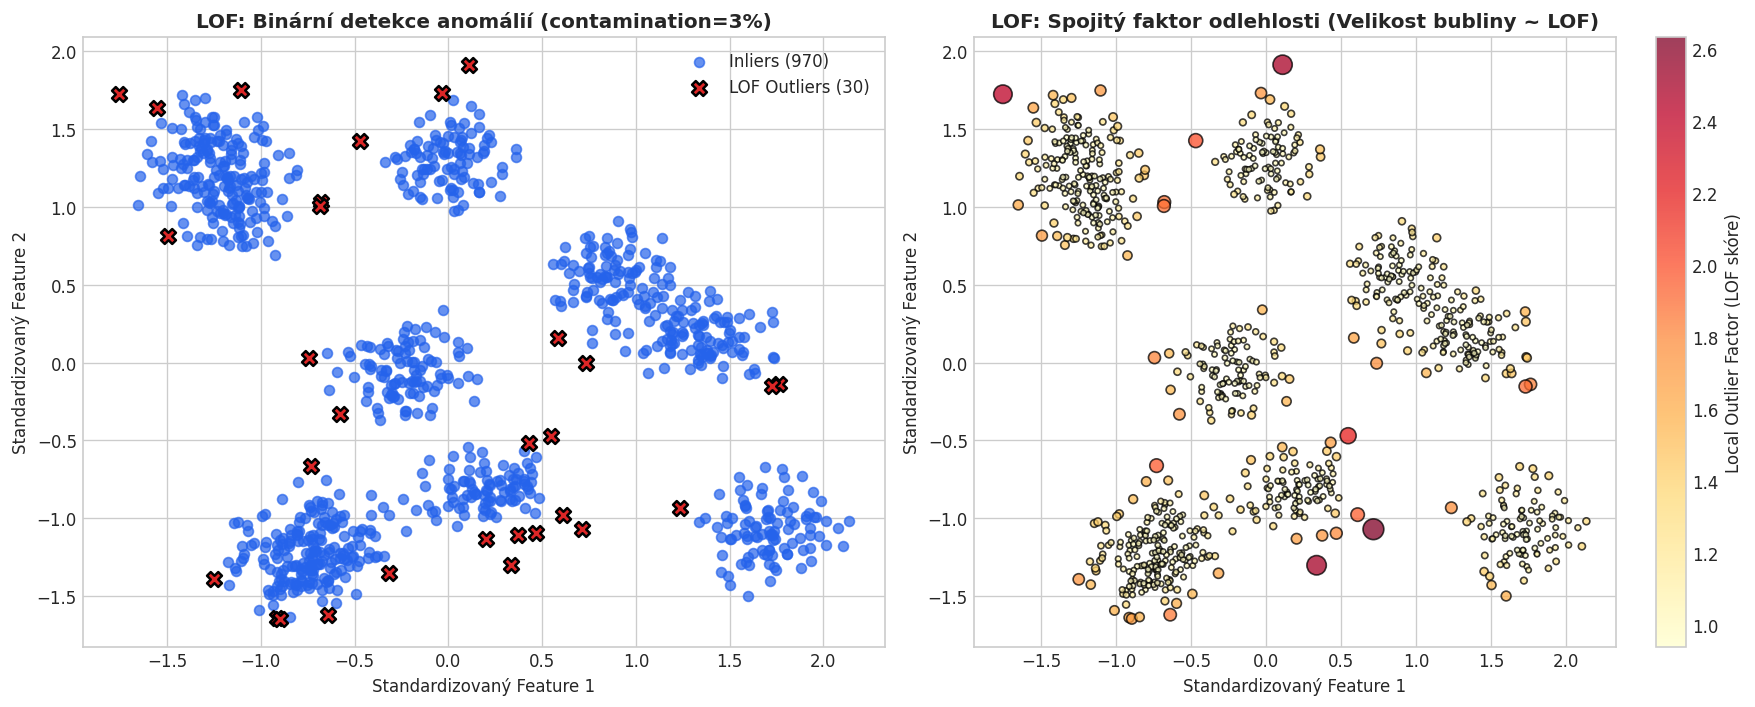

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Graf 1: Binární klasifikace Inlier / Outlier
ax1.scatter(X_blobs_scaled[labels == 1, 0], X_blobs_scaled[labels == 1, 1], c='#2563eb', s=35, alpha=0.7, label=f'Inliers ({n_inliers})')
ax1.scatter(X_blobs_scaled[labels == -1, 0], X_blobs_scaled[labels == -1, 1], c='#dc2626', s=80, marker='X', edgecolors='black', lw=1.5, label=f'LOF Outliers ({n_outliers})')
ax1.set_title('LOF: Binární detekce anomálií (contamination=3%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Standardizovaný Feature 1')
ax1.set_ylabel('Standardizovaný Feature 2')
ax1.legend()

# Graf 2: Bublinový graf LOF skóre
# Poloměr bubliny úměrný (LOF - 1)^2 pro dramatické zvýraznění anomálií
radius = 10 + 60 * np.maximum(0, lof_scores - 1)**1.8
scatter = ax2.scatter(X_blobs_scaled[:, 0], X_blobs_scaled[:, 1], s=radius, c=lof_scores, cmap='YlOrRd', edgecolors='k', alpha=0.75)
cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label('Local Outlier Factor (LOF skóre)', fontsize=10)
ax2.set_title('LOF: Spojitý faktor odlehlosti (Velikost bubliny ~ LOF)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Standardizovaný Feature 1')
ax2.set_ylabel('Standardizovaný Feature 2')

plt.tight_layout()
plt.show()

## 4. Srovnání metodik: LOF vs. Isolation Forest

Porovnáme hustotní metodu LOF se stromovým ansámblem Isolation Forest na stejném datasetu se shodnou kontaminací ($3\,\%$).

In [5]:
iforest = IsolationForest(contamination=0.03, random_state=42)
if_labels = iforest.fit_predict(X_blobs_scaled)

# Křížová tabulka shody
ct = pd.crosstab(
    pd.Series(labels, name='LOF'),
    pd.Series(if_labels, name='Isolation Forest'),
    rownames=['LOF (-1=Outlier)'],
    colnames=['iForest (-1=Outlier)']
)
print('Křížová tabulka shody obou algoritmů:')
print(ct)

both_outliers = np.sum((labels == -1) & (if_labels == -1))
print(f'Oba modely se shodly na {both_outliers} z 30 anomálií ({both_outliers/30*100:.1f} % shoda).')

Křížová tabulka shody obou algoritmů:
iForest (-1=Outlier)  -1    1
LOF (-1=Outlier)             
-1                     9   21
 1                    21  949
Oba modely se shodly na 9 z 30 anomálií (30.0 % shoda).


## 5. Klíčová výhoda LOF: Různé lokální hustoty (Varying Density Benchmark)

Vytvoříme syntetický scénář se dvěma shluky o diametrálně odlišné hustotě:
- Shluk $C_1$: Velmi hustý (rozptyl 0.25)
- Shluk $C_2$: Velmi řídký (rozptyl 0.85)
- **Lokální anomálie:** Body ležící v těsné blízkosti $C_1$, jejichž vzdálenost k $C_1$ je menší než běžná mezibodová vzdálenost uvnitř $C_2$!
- **Globální anomálie:** Extrémní body daleko od obou shluků.

C:\Users\xeen\AppData\Local\Temp\ipykernel_17400\3628939257.py:39: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xeen\AppData\Local\Temp\ipykernel_17400\3628939257.py:39: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xeen\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\xeen\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


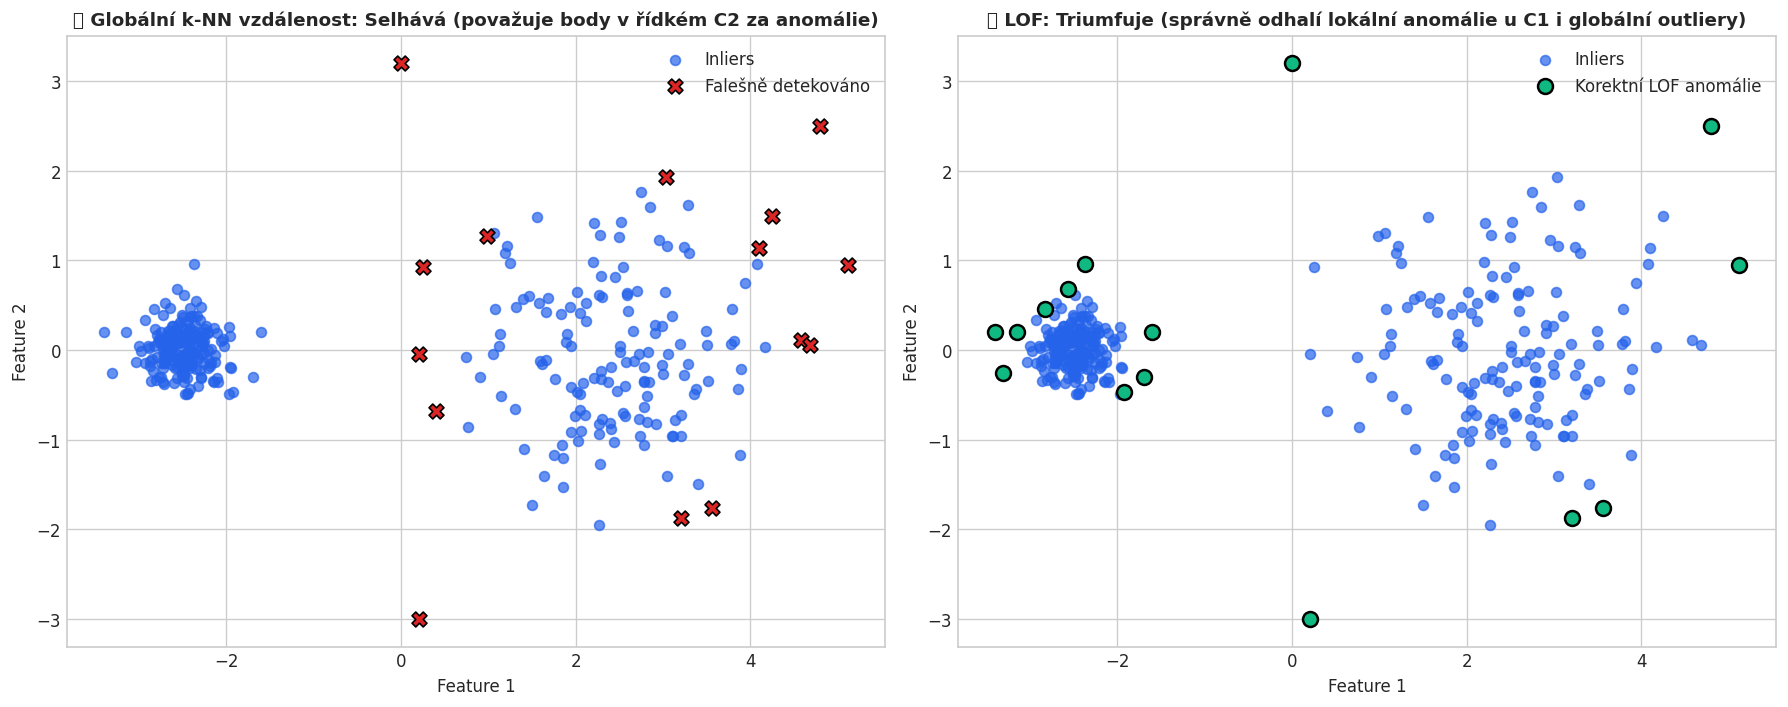

In [6]:
np.random.seed(42)
c1 = np.random.normal(loc=[-2.5, 0.0], scale=0.25, size=(200, 2))
c2 = np.random.normal(loc=[2.5, 0.0], scale=0.85, size=(150, 2))
local_anom = np.array([[-1.6, 0.2], [-1.7, -0.3], [-3.4, 0.2]])
global_anom = np.array([[0.0, 3.2], [0.2, -3.0], [4.8, 2.5]])

X_bench = np.vstack([c1, c2, local_anom, global_anom])

# 1. Globální k-NN distance (bez hustotní normalizace)
knn = NearestNeighbors(n_neighbors=25).fit(X_bench)
dists, _ = knn.kneighbors(X_bench)
global_dist_score = dists[:, -1]
global_threshold = np.percentile(global_dist_score, 96)
global_outliers = global_dist_score >= global_threshold

# 2. LOF (s lokální hustotní normalizací)
lof_bench = LocalOutlierFactor(n_neighbors=25, contamination=0.04)
lof_bench_labels = lof_bench.fit_predict(X_bench)
lof_bench_outliers = (lof_bench_labels == -1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Graf 1: Globální vzdálenost selhává
ax1.scatter(X_bench[~global_outliers, 0], X_bench[~global_outliers, 1], c='#2563eb', s=35, alpha=0.7, label='Inliers')
ax1.scatter(X_bench[global_outliers, 0], X_bench[global_outliers, 1], c='#dc2626', s=80, marker='X', edgecolors='k', label='Falešně detekováno')
ax1.set_title('❌ Globální k-NN vzdálenost: Selhává (považuje body v řídkém C2 za anomálie)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Feature 2')
ax1.legend()

# Graf 2: LOF triumfuje
ax2.scatter(X_bench[~lof_bench_outliers, 0], X_bench[~lof_bench_outliers, 1], c='#2563eb', s=35, alpha=0.7, label='Inliers')
ax2.scatter(X_bench[lof_bench_outliers, 0], X_bench[lof_bench_outliers, 1], c='#10b981', s=80, marker='o', edgecolors='k', lw=1.5, label='Korektní LOF anomálie')
ax2.set_title('✅ LOF: Triumfuje (správně odhalí lokální anomálie u C1 i globální outliery)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Feature 1')
ax2.set_ylabel('Feature 2')
ax2.legend()

plt.tight_layout()
plt.show()

## 6. Režim Novelty Detection (Predikce na nových datech)

Pokud chceme model nasadit do produkční pipeline pro vyhodnocování nových příchozích dat v reálném čase, musíme nastavit `novelty=True`.

In [7]:
# Trénování na čistých datech s novelty=True
lof_novelty = LocalOutlierFactor(n_neighbors=20, novelty=True)
lof_novelty.fit(X_blobs_scaled)

# Nová testovací data: 1 normální bod a 1 extrémní anomálie
X_new = np.array([
    [0.1, 0.2],   # Normální bod uprostřed distribuce
    [4.5, -4.0]   # Extrémní nová anomálie
])

new_preds = lof_novelty.predict(X_new)
new_scores = lof_novelty.decision_function(X_new)

for i, (pred, score) in enumerate(zip(new_preds, new_scores)):
    stav = '✅ Normální bod (Inlier)' if pred == 1 else '🚨 Detekována Nová Anomálie (Outlier)'
    print(f'Vzorek {i+1} {X_new[i]}: {stav} | Decision Function skóre: {score:.4f}')

Vzorek 1 [0.1 0.2]: ✅ Normální bod (Inlier) | Decision Function skóre: 0.0600
Vzorek 2 [ 4.5 -4. ]: 🚨 Detekována Nová Anomálie (Outlier) | Decision Function skóre: -19.0113
